# Data analysis - Software Component nr. 2

This notebook will be the support for **Software Component nr. 2**, a document that will contain the following:

1. Analysis of the features used in learning:
    - correlation
    - independence
    - feature importance
2. Data statistics
3. Data distribution
4. Data visualization and interpretation

In [1]:
from pathlib import Path

import pandas as pd

## Converting the raw data to CSV

The UCI HAR dataset ships as whitespace-separated text files, with the features, the labels and the subjects in separate files. The cells below join them into one table per split, `train.csv` and `test.csv`, with the columns `subject`, `activity_id`, `activity` and then the 561 features.

The raw `Inertial Signals` are left out, because the project works on the features that are already extracted.

In [2]:
RAW_DIR = Path.home() / "Documents/Master/Anul I/Sem I/ML/Project/Dataset/human+activity+recognition+using+smartphones/UCI HAR Dataset/UCI HAR Dataset"
CSV_DIR = Path("../data")

CSV_DIR.mkdir(exist_ok=True)

`features.txt` contains 42 names that appear three times each (the `bandsEnergy()` features). Column names must be unique, so these get a suffix with the order of their occurrence: `_1`, `_2`, `_3`. All the other names stay as they are in the dataset.

In [3]:
features = pd.read_csv(RAW_DIR / "features.txt", sep=" ", header=None, names=["index", "name"])["name"]

is_duplicate = features.duplicated(keep=False)
occurrence = features.groupby(features).cumcount() + 1
feature_names = features.where(~is_duplicate, features + "_" + occurrence.astype(str)).tolist()

assert len(set(feature_names)) == 561
print(f"{features[is_duplicate].nunique()} names repeated, {is_duplicate.sum()} columns renamed")
print(features[is_duplicate].value_counts().unique())

activity_labels = pd.read_csv(RAW_DIR / "activity_labels.txt", sep=" ", header=None, index_col=0).iloc[:, 0]
activity_labels

42 names repeated, 126 columns renamed
[3]


0
1               WALKING
2      WALKING_UPSTAIRS
3    WALKING_DOWNSTAIRS
4               SITTING
5              STANDING
6                LAYING
Name: 1, dtype: str

In [4]:
def read_column(path):
    return pd.read_csv(path, header=None).iloc[:, 0]


def load_split(split):
    split_dir = RAW_DIR / split
    X = pd.read_csv(split_dir / f"X_{split}.txt", sep=r"\s+", header=None, names=feature_names)
    activity_id = read_column(split_dir / f"y_{split}.txt")
    meta = pd.DataFrame({
        "subject": read_column(split_dir / f"subject_{split}.txt"),
        "activity_id": activity_id,
        "activity": activity_id.map(activity_labels),
    })
    return pd.concat([meta, X], axis=1)


splits = {split: load_split(split) for split in ["train", "test"]}

for split, df in splits.items():
    df.to_csv(CSV_DIR / f"{split}.csv", index=False)
    print(split, df.shape)

train (7352, 564)
test (2947, 564)


Checking that the CSV files match the data that was loaded from the raw files.

In [5]:
for split, df in splits.items():
    csv = pd.read_csv(CSV_DIR / f"{split}.csv")
    pd.testing.assert_frame_equal(df, csv, check_exact=True)
    assert csv.notna().all().all()
    print(f"{split}: {csv.shape}, {(CSV_DIR / f'{split}.csv').stat().st_size / 1e6:.0f} MB, {csv['subject'].nunique()} subjects")

assert not set(splits["train"]["subject"]) & set(splits["test"]["subject"])

pd.DataFrame({split: df["activity"].value_counts() for split, df in splits.items()})

train: (7352, 564), 48 MB, 21 subjects
test: (2947, 564), 19 MB, 9 subjects


,train,test
activity,,
LAYING,1407,537
SITTING,1286,491
STANDING,1374,532
WALKING,1226,496
WALKING_DOWNSTAIRS,986,420
WALKING_UPSTAIRS,1073,471


In [6]:
splits["train"].iloc[:5, :6]

,subject,activity_id,activity,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z
0,1,5,STANDING,0.288585,-0.020294,-0.132905
1,1,5,STANDING,0.278419,-0.016411,-0.123520
2,1,5,STANDING,0.279653,-0.019467,-0.113462
3,1,5,STANDING,0.279174,-0.026201,-0.123283
4,1,5,STANDING,0.276629,-0.016570,-0.115362


## 1. Analysis of the features used in learning

### Correlation

The analysis uses all 10,299 instances, from both the training and the test files.

The Pearson coefficient measures the degree of linear relationship between two features. It takes values between -1 and 1: the sign gives the direction of the relationship, and the distance from 0 gives its strength.

In [7]:
data = pd.concat([pd.read_csv(CSV_DIR / f"{split}.csv") for split in ["train", "test"]], ignore_index=True)
X = data.drop(columns=["subject", "activity_id", "activity"])

In [8]:
pearson = X.corr(method="pearson")

print(pearson.shape)
pearson

(561, 561)


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
tBodyAcc-mean()-X,1.000000,0.128037,-0.230302,0.004590,-0.016785,-0.036071,0.010303,-0.017488,-0.038805,0.046943,...,0.029901,-0.006179,-0.002255,-0.552989,0.015754,0.036047,0.034296,-0.041021,0.034053,0.030656
tBodyAcc-mean()-Y,0.128037,1.000000,-0.029882,-0.046352,-0.046996,-0.054153,-0.045247,-0.047673,-0.055524,-0.039445,...,-0.014402,-0.000649,-0.002842,0.077750,-0.027567,0.013241,0.077627,-0.007513,-0.005616,-0.016233
tBodyAcc-mean()-Z,-0.230302,-0.029882,1.000000,-0.024185,-0.023745,-0.015632,-0.022872,-0.022966,-0.009577,-0.040218,...,-0.015358,0.023050,0.023122,0.055020,-0.042083,-0.066233,-0.030748,0.003215,-0.012986,-0.028406
tBodyAcc-std()-X,0.004590,-0.046352,-0.024185,1.000000,0.922525,0.861910,0.998662,0.916087,0.856497,0.981226,...,-0.068807,0.165552,0.135171,-0.034334,-0.017096,0.027464,-0.027123,-0.374104,0.449425,0.393063
tBodyAcc-std()-Y,-0.016785,-0.046996,-0.023745,0.922525,1.000000,0.888259,0.918561,0.997510,0.887052,0.911137,...,-0.109941,0.220279,0.191164,-0.020806,-0.006605,0.001902,-0.015784,-0.381391,0.506106,0.425511
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"angle(tBodyGyroMean,gravityMean)",0.036047,0.013241,-0.066233,0.027464,0.001902,-0.004984,0.027729,-0.002924,-0.009873,0.033533,...,-0.029273,0.042123,0.035684,-0.013009,0.010679,1.000000,-0.112454,-0.007095,-0.006444,-0.015380
"angle(tBodyGyroJerkMean,gravityMean)",0.034296,0.077627,-0.030748,-0.027123,-0.015784,-0.012196,-0.027097,-0.013411,-0.012800,-0.030908,...,-0.002618,-0.013065,-0.011829,-0.027478,0.023605,-0.112454,1.000000,0.024822,-0.004582,-0.012549
"angle(X,gravityMean)",-0.041021,-0.007513,0.003215,-0.374104,-0.381391,-0.353271,-0.371168,-0.378013,-0.355836,-0.384244,...,0.087571,-0.085226,-0.081971,0.008050,0.017534,-0.007095,0.024822,1.000000,-0.748249,-0.635231
"angle(Y,gravityMean)",0.034053,-0.005616,-0.012986,0.449425,0.506106,0.459092,0.444926,0.507947,0.460345,0.458832,...,-0.105752,0.087671,0.078010,0.003082,-0.007256,-0.006444,-0.004582,-0.748249,1.000000,0.545614


The Spearman coefficient measures the strength and direction of the monotonic relationship between two features, meaning how consistently one feature rises or falls as the other rises, even if the relationship is not linear. It is computed as the Pearson coefficient on the ranks of the values instead of the values themselves, so it is less affected by skewed distributions and outliers. It takes values between -1 and 1: the sign gives the direction of the relationship, and the distance from 0 gives its strength.

In [9]:
spearman = X.corr(method="spearman")

print(spearman.shape)
spearman

(561, 561)


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
tBodyAcc-mean()-X,1.000000,0.022295,-0.083427,-0.009568,-0.012646,-0.025704,-0.005073,-0.011029,-0.024686,0.038790,...,0.021887,-0.001505,0.000878,-0.682582,0.036812,0.022798,0.034842,-0.035061,-0.002395,-0.002435
tBodyAcc-mean()-Y,0.022295,1.000000,0.133755,-0.053400,-0.058923,-0.055783,-0.054001,-0.061826,-0.057147,-0.046191,...,0.010234,0.003970,0.005618,0.149897,-0.077929,0.000707,0.134426,-0.020782,-0.020082,-0.006800
tBodyAcc-mean()-Z,-0.083427,0.133755,1.000000,-0.030216,-0.047128,-0.042270,-0.028686,-0.049877,-0.038676,-0.043321,...,0.011078,-0.008392,-0.007863,0.073690,-0.066986,-0.086583,-0.060467,-0.008811,-0.027673,-0.032988
tBodyAcc-std()-X,-0.009568,-0.053400,-0.030216,1.000000,0.886651,0.859698,0.998209,0.880746,0.853306,0.970649,...,-0.252859,0.290803,0.269906,-0.006685,-0.012908,0.034157,-0.019933,-0.110363,0.429159,0.340034
tBodyAcc-std()-Y,-0.012646,-0.058923,-0.047128,0.886651,1.000000,0.881082,0.883073,0.996746,0.877776,0.872612,...,-0.287870,0.319217,0.300673,-0.001335,-0.004947,0.003711,-0.010419,-0.231972,0.600977,0.455685
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"angle(tBodyGyroMean,gravityMean)",0.022798,0.000707,-0.086583,0.034157,0.003711,0.001432,0.034187,0.000219,-0.002911,0.039490,...,-0.034554,0.045674,0.040910,-0.008051,0.009192,1.000000,-0.121480,-0.029621,-0.016889,-0.011112
"angle(tBodyGyroJerkMean,gravityMean)",0.034842,0.134426,-0.060467,-0.019933,-0.010419,-0.010309,-0.020067,-0.008647,-0.011184,-0.024529,...,-0.000265,-0.011922,-0.009878,-0.026827,0.020847,-0.121480,1.000000,0.038198,0.001993,-0.013379
"angle(X,gravityMean)",-0.035061,-0.020782,-0.008811,-0.110363,-0.231972,-0.217687,-0.101763,-0.225440,-0.220339,-0.150806,...,0.095582,-0.106143,-0.105079,0.009206,0.021645,-0.029621,0.038198,1.000000,-0.172718,-0.269444
"angle(Y,gravityMean)",-0.002395,-0.020082,-0.027673,0.429159,0.600977,0.516419,0.422371,0.608552,0.516996,0.449120,...,-0.124956,0.089551,0.086655,0.011045,0.000597,-0.016889,0.001993,-0.172718,1.000000,0.571553


#### Summary of the correlations

Each pair of features is counted once, so only the values above the diagonal of each matrix are used.

In [10]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform

CORRELATION_DIR = CSV_DIR / "analysis" / "correlation"
CORRELATION_DIR.mkdir(parents=True, exist_ok=True)

In [11]:
upper = np.triu_indices(X.shape[1], k=1)
pearson_pairs = pearson.to_numpy()[upper]
spearman_pairs = spearman.to_numpy()[upper]


def count_pairs(values):
    strength = np.abs(values)
    counts = {f"|r| >= {t}": (strength >= t).sum() for t in [0.5, 0.8, 0.9, 0.95, 0.99]}
    counts["|r| < 0.2"] = (strength < 0.2).sum()
    return pd.Series(counts)


summary = pd.DataFrame({"Pearson": count_pairs(pearson_pairs), "Spearman": count_pairs(spearman_pairs)})
summary["Pearson %"] = (summary["Pearson"] / len(pearson_pairs) * 100).round(1)
summary["Spearman %"] = (summary["Spearman"] / len(spearman_pairs) * 100).round(1)

print(f"{len(pearson_pairs)} pairs of features")
print(f"Median |r|: Pearson {np.median(np.abs(pearson_pairs)):.2f}, Spearman {np.median(np.abs(spearman_pairs)):.2f}")
summary

157080 pairs of features
Median |r|: Pearson 0.38, Spearman 0.58


,Pearson,Spearman,Pearson %,Spearman %
|r| >= 0.5,64879,85093,41.3,54.2
|r| >= 0.8,22815,61248,14.5,39.0
|r| >= 0.9,8093,27130,5.2,17.3
|r| >= 0.95,2219,4249,1.4,2.7
|r| >= 0.99,207,492,0.1,0.3
|r| < 0.2,51275,40444,32.6,25.7


#### Notable features and pairs

Some features contain exactly the same values under different names. Each group of identical features is listed once.

In [12]:
fingerprint = pd.util.hash_pandas_object(X.T, index=False)
is_copy = fingerprint.duplicated()

identical = fingerprint.index.to_series().groupby(fingerprint.values).agg(list)
identical = identical[identical.str.len() > 1]

print(f"{(~is_copy).sum()} distinct features, {is_copy.sum()} redundant copies, {len(identical)} groups of identical features")
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame({"Identical features": identical.map(", ".join)}).reset_index(drop=True))

540 distinct features, 21 redundant copies, 19 groups of identical features


,Identical features
0,"fBodyBodyGyroJerkMag-mean(), fBodyBodyGyroJerkMag-sma()"
1,"tBodyAccJerkMag-mean(), tBodyAccJerkMag-sma()"
2,"tBodyAccMag-mad(), tGravityAccMag-mad()"
3,"tBodyAccMag-max(), tGravityAccMag-max()"
4,"tBodyAccMag-arCoeff()1, tGravityAccMag-arCoeff()1"
5,"tBodyAccMag-iqr(), tGravityAccMag-iqr()"
6,"tBodyGyroMag-mean(), tBodyGyroMag-sma()"
7,"tBodyAccMag-arCoeff()2, tGravityAccMag-arCoeff()2"
8,"tBodyAccMag-std(), tGravityAccMag-std()"
9,"tBodyAccMag-min(), tGravityAccMag-min()"


The tables below keep only one feature from each group of identical features, so that their correlation of exactly 1 does not fill the rankings.

In [13]:
pairs = pd.DataFrame({
    "feature_1": X.columns[upper[0]],
    "feature_2": X.columns[upper[1]],
    "pearson": pearson_pairs,
    "spearman": spearman_pairs,
})
distinct = fingerprint.index[~is_copy]
pairs = pairs[pairs["feature_1"].isin(distinct) & pairs["feature_2"].isin(distinct)]

pairs.nlargest(10, "pearson")

,feature_1,feature_2,pearson,spearman
50390,tBodyAccJerk-energy()-Z,fBodyAccJerk-energy()-Z,1.000000,0.999986
49927,tBodyAccJerk-energy()-Y,fBodyAccJerk-energy()-Y,1.000000,0.999985
49463,tBodyAccJerk-energy()-X,fBodyAccJerk-energy()-X,0.999999,0.999994
118052,fBodyAcc-energy()-X,"fBodyAcc-bandsEnergy()-1,24_1",0.999864,0.999757
149731,fBodyGyro-energy()-X,"fBodyGyro-bandsEnergy()-1,24_1",0.999773,0.999895
118344,fBodyAcc-energy()-Y,"fBodyAcc-bandsEnergy()-1,24_2",0.999635,0.999739
9104,tBodyAcc-energy()-X,fBodyAcc-energy()-X,0.999633,0.998831
48865,tBodyAccJerk-sma(),tBodyAccJerkMag-mean(),0.999615,0.999389
9137,tBodyAcc-energy()-X,"fBodyAcc-bandsEnergy()-1,24_1",0.999514,0.998642
149998,fBodyGyro-energy()-Z,"fBodyGyro-bandsEnergy()-1,24_3",0.999486,0.999795


In [14]:
pairs.nsmallest(10, "pearson")

,feature_1,feature_2,pearson,spearman
38252,"tGravityAcc-arCoeff()-Z,1","tGravityAcc-arCoeff()-Z,2",-0.995195,-0.994920
23176,tGravityAcc-mean()-Z,"angle(Z,gravityMean)",-0.994764,-0.999982
38739,"tGravityAcc-arCoeff()-Z,2","tGravityAcc-arCoeff()-Z,3",-0.994628,-0.994102
39225,"tGravityAcc-arCoeff()-Z,3","tGravityAcc-arCoeff()-Z,4",-0.994267,-0.993546
22657,tGravityAcc-mean()-Y,"angle(Y,gravityMean)",-0.993425,-0.999937
27793,tGravityAcc-max()-Z,"angle(Z,gravityMean)",-0.992689,-0.995995
36294,"tGravityAcc-arCoeff()-Y,1","tGravityAcc-arCoeff()-Y,2",-0.991609,-0.991333
27283,tGravityAcc-max()-Y,"angle(Y,gravityMean)",-0.991255,-0.995521
29314,tGravityAcc-min()-Z,"angle(Z,gravityMean)",-0.990748,-0.994350
28807,tGravityAcc-min()-Y,"angle(Y,gravityMean)",-0.990459,-0.993683


The pairs with the largest difference have a strong monotonic relationship that is not linear, which Pearson underestimates.

In [15]:
pairs = pairs.assign(difference=pairs["spearman"].abs() - pairs["pearson"].abs())

print(f"Pairs with Spearman |r| >= 0.8 and Pearson |r| < 0.5: {((pairs['spearman'].abs() >= 0.8) & (pairs['pearson'].abs() < 0.5)).sum()}")
pairs.nlargest(10, "difference")

Pairs with Spearman |r| >= 0.8 and Pearson |r| < 0.5: 3983


,feature_1,feature_2,pearson,spearman,difference
23435,tGravityAcc-std()-X,"fBodyAcc-bandsEnergy()-1,8_1",0.146628,0.769328,0.622700
23443,tGravityAcc-std()-X,"fBodyAcc-bandsEnergy()-1,16_1",0.142013,0.756582,0.614569
24980,tGravityAcc-mad()-X,"fBodyAcc-bandsEnergy()-1,8_1",0.148223,0.762780,0.614557
23447,tGravityAcc-std()-X,"fBodyAcc-bandsEnergy()-1,24_1",0.139760,0.751328,0.611568
23414,tGravityAcc-std()-X,fBodyAcc-energy()-X,0.139573,0.749725,0.610152
153340,"fBodyGyro-bandsEnergy()-1,8_2","fBodyGyro-bandsEnergy()-17,24_2",0.273461,0.881346,0.607886
142289,"fBodyAccJerk-bandsEnergy()-57,64_1","fBodyGyro-bandsEnergy()-17,24_2",0.210790,0.817983,0.607193
24988,tGravityAcc-mad()-X,"fBodyAcc-bandsEnergy()-1,16_1",0.143707,0.750168,0.606461
24992,tGravityAcc-mad()-X,"fBodyAcc-bandsEnergy()-1,24_1",0.141489,0.744953,0.603463
24959,tGravityAcc-mad()-X,fBodyAcc-energy()-X,0.141302,0.743339,0.602037


#### Heatmaps

The features are ordered with hierarchical clustering on the Pearson matrix, so that strongly related features sit next to each other and appear as blocks. Both heatmaps use the same order, so they can be compared directly. The 561 feature names are left out, because they cannot be read at this size.

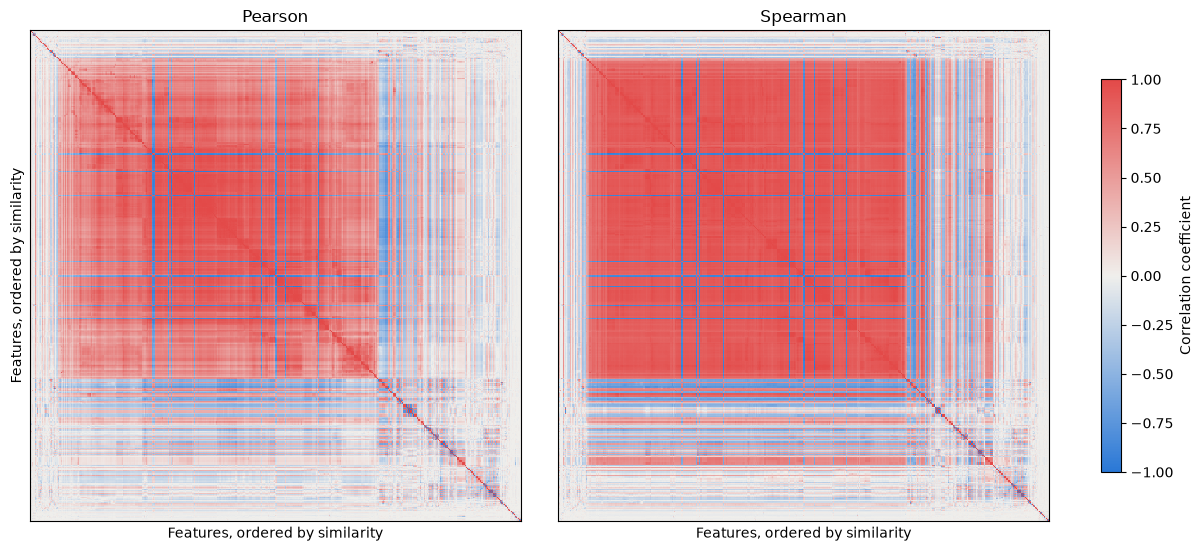

In [16]:
distance = squareform(np.clip(1 - pearson.abs().to_numpy(), 0, None), checks=False)
order = leaves_list(linkage(distance, method="average", optimal_ordering=True))

colormap = LinearSegmentedColormap.from_list("correlation", ["#2a78d6", "#f0efec", "#e34948"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5.4), layout="constrained")
for ax, name, matrix in zip(axes, ["Pearson", "Spearman"], [pearson, spearman]):
    image = ax.imshow(matrix.to_numpy()[np.ix_(order, order)], cmap=colormap, vmin=-1, vmax=1, interpolation="nearest")
    ax.set_title(name)
    ax.set_xlabel("Features, ordered by similarity")
    ax.set_xticks([])
    ax.set_yticks([])
axes[0].set_ylabel("Features, ordered by similarity")
fig.colorbar(image, ax=axes, shrink=0.8, label="Correlation coefficient")

fig.savefig(CORRELATION_DIR / "correlation_heatmaps.png", dpi=300)
plt.show()

### Independence

Two random variables are independent if they convey no information about each other. Pearson's chi-squared test checks this for two categorical variables, by comparing the observed counts in each combination of categories with the counts expected if the variables were independent. The null hypothesis is that the variables are independent, so a small p-value means that independence is rejected.

The features are continuous, so each one is first split into bins with an equal number of instances. Features with many repeated values can end up with fewer bins than requested.

With 10,299 instances, even very small dependencies give very small p-values, so each test also reports Cramér's V, which measures the strength of the dependency between 0 (none) and 1 (complete). The significance level of 0.05 is divided by the number of tests (Bonferroni correction), because some tests would otherwise come out significant by chance.

The test assumes independent instances, but the windows overlap by 50% and come from the same volunteers, so the p-values look stronger than they are.

In [17]:
from scipy.stats import chi2_contingency

INDEPENDENCE_DIR = CSV_DIR / "analysis" / "independence"
INDEPENDENCE_DIR.mkdir(parents=True, exist_ok=True)


def contingency_table(a, b):
    rows, columns = a.max() + 1, b.max() + 1
    return np.bincount(a * columns + b, minlength=rows * columns).reshape(rows, columns)


def chi_squared_test(a, b):
    table = contingency_table(a, b)
    chi2, p_value, _, _ = chi2_contingency(table, correction=False)
    cramers_v = np.sqrt(chi2 / (table.sum() * (min(table.shape) - 1)))
    return chi2, p_value, cramers_v

#### Feature vs. activity

Each feature is split into 10 bins and tested against the 6 activities. A feature that is independent of the activity says nothing about which activity is being performed.

In [18]:
activity = data["activity_id"].to_numpy() - 1
binned_10 = X.apply(lambda column: pd.qcut(column, 10, labels=False, duplicates="drop"))

feature_activity = pd.DataFrame(
    [chi_squared_test(binned_10[feature].to_numpy(), activity) for feature in X.columns],
    index=X.columns,
    columns=["chi2", "p_value", "cramers_v"],
).sort_values("cramers_v", ascending=False)
feature_activity["bins"] = binned_10.nunique()

alpha = 0.05 / len(feature_activity)
print(f"{(feature_activity['p_value'] < alpha).sum()} of {len(feature_activity)} features: independence rejected (alpha = {alpha:.1e})")
print(f"Features with fewer than 10 bins: {(feature_activity['bins'] < 10).sum()}")
print(feature_activity["cramers_v"].describe().round(3).to_string())

feature_activity.to_csv(INDEPENDENCE_DIR / "feature_activity.csv")
feature_activity.head(10)

561 of 561 features: independence rejected (alpha = 8.9e-05)
Features with fewer than 10 bins: 20
count    561.000
mean       0.393
std        0.118
min        0.058
25%        0.321
50%        0.447
75%        0.472
max        0.570


,chi2,p_value,cramers_v,bins
"fBodyAcc-bandsEnergy()-1,8_1",16739.823177,0.0,0.570155,10
"fBodyAcc-bandsEnergy()-1,16_1",16219.923802,0.0,0.561231,10
fBodyAccMag-mad(),16060.670886,0.0,0.558469,10
fBodyAcc-std()-X,16040.936542,0.0,0.558126,10
fBodyAccMag-std(),15983.800148,0.0,0.557131,10
tBodyAcc-max()-X,15966.460803,0.0,0.556829,10
"fBodyAcc-bandsEnergy()-1,24_1",15931.129888,0.0,0.556213,10
tBodyAcc-energy()-X,15901.563755,0.0,0.555696,10
fBodyAcc-energy()-X,15866.265683,0.0,0.555079,10
tBodyAcc-std()-X,15866.265683,0.0,0.555079,10


In [19]:
feature_activity.tail(10)

,chi2,p_value,cramers_v,bins
"tBodyAccJerk-arCoeff()-X,2",571.607619,2.183681e-92,0.105358,10
tBodyGyroMag-arCoeff()3,569.310227,6.318278e-92,0.105146,10
tBodyGyroMag-arCoeff()4,539.087474,7.178501e-86,0.102317,10
"tBodyGyro-arCoeff()-X,3",526.840768,2.002965e-83,0.101148,10
"tBodyGyroJerk-correlation()-X,Z",489.116127,6.348711e-76,0.097459,10
"tBodyAcc-arCoeff()-Y,4",372.196300,4.507584e-53,0.085017,10
tBodyGyroJerkMag-arCoeff()3,352.875974,2.262815e-49,0.082781,10
"tBodyGyroJerk-arCoeff()-Y,4",337.829764,1.650725e-46,0.080997,10
tBodyAccJerkMag-arCoeff()3,327.098216,1.772668e-44,0.079700,10
"tBodyGyroJerk-arCoeff()-X,4",175.302225,2.792375e-17,0.058346,10


#### Feature vs. feature

Each of the distinct features is split into 5 bins and tested against every other distinct feature. Fewer bins are used here to keep the tables small, since there are many more tests.

In [20]:
binned_5 = X[distinct].apply(lambda column: pd.qcut(column, 5, labels=False, duplicates="drop"))
codes = {feature: binned_5[feature].to_numpy() for feature in distinct}

results = [chi_squared_test(codes[a], codes[b]) for a, b in zip(pairs["feature_1"], pairs["feature_2"])]
pairs[["chi2", "p_value", "cramers_v"]] = results

alpha = 0.05 / len(pairs)
print(f"{(pairs['p_value'] < alpha).sum()} of {len(pairs)} pairs: independence rejected (alpha = {alpha:.1e})")
print(f"Features with fewer than 5 bins: {(binned_5.nunique() < 5).sum()}")
print(pairs["cramers_v"].describe().round(3).to_string())

pairs.to_csv(INDEPENDENCE_DIR / "feature_feature.csv", index=False)
pairs.nlargest(10, "cramers_v")

144190 of 145530 pairs: independence rejected (alpha = 3.4e-07)
Features with fewer than 5 bins: 17
count    145530.000
mean          0.355
std           0.191
min           0.012
25%           0.186
50%           0.339
75%           0.531
max           1.000


,feature_1,feature_2,pearson,spearman,difference,chi2,p_value,cramers_v
2511,tBodyAcc-std()-Y,fBodyAcc-energy()-Y,0.961489,1.0,0.038511,41196.000000,0.0,1.000000
3067,tBodyAcc-std()-Z,fBodyAcc-energy()-Z,0.941535,1.0,0.058465,41196.000000,0.0,1.000000
43830,tBodyAccJerk-std()-Y,fBodyAccJerk-energy()-Y,0.954383,1.0,0.045617,41196.000000,0.0,1.000000
44306,tBodyAccJerk-std()-Z,fBodyAccJerk-energy()-Z,0.924469,1.0,0.075531,41196.000000,0.0,1.000000
61692,tBodyGyro-std()-X,fBodyGyro-energy()-X,0.928756,1.0,0.071244,41196.000000,0.0,1.000000
62129,tBodyGyro-std()-Y,fBodyGyro-energy()-Y,0.927298,1.0,0.072702,41196.000000,0.0,1.000000
62565,tBodyGyro-std()-Z,fBodyGyro-energy()-Z,0.925400,1.0,0.074600,41196.000000,0.0,1.000000
43353,tBodyAccJerk-std()-X,fBodyAccJerk-energy()-X,0.949418,1.0,0.050582,41176.011650,0.0,0.999757
1954,tBodyAcc-std()-X,fBodyAcc-energy()-X,0.948325,1.0,0.051675,41176.006798,0.0,0.999757
92766,tBodyAccMag-std(),fBodyAccMag-energy(),0.950208,1.0,0.049792,41176.006798,0.0,0.999757


Independence implies uncorrelation, but uncorrelation does not imply independence. The pairs below have both correlation coefficients close to 0, but they still have the strongest dependencies among such pairs.

In [21]:
uncorrelated = pairs[(pairs["pearson"].abs() < 0.1) & (pairs["spearman"].abs() < 0.1)]

print(f"{len(uncorrelated)} pairs with Pearson and Spearman |r| < 0.1")
print(f"Independence rejected for {(uncorrelated['p_value'] < alpha).sum()} of them")
uncorrelated.nlargest(10, "cramers_v")

19605 pairs with Pearson and Spearman |r| < 0.1
Independence rejected for 18271 of them


,feature_1,feature_2,pearson,spearman,difference,chi2,p_value,cramers_v
77186,tBodyGyroJerk-mean()-X,"fBodyGyro-bandsEnergy()-57,64_1",0.057053,0.010120,-0.046933,13868.697594,0.0,0.580217
78011,tBodyGyroJerk-mean()-Z,"fBodyGyro-bandsEnergy()-57,64_3",0.011541,-0.008310,-0.003231,13413.957048,0.0,0.570625
77599,tBodyGyroJerk-mean()-Y,"fBodyGyro-bandsEnergy()-57,64_2",0.003356,-0.021786,0.018430,12750.965004,0.0,0.556345
42361,tBodyAccJerk-mean()-Y,"fBodyAcc-bandsEnergy()-57,64_2",-0.034350,-0.029862,-0.004488,11837.889082,0.0,0.536055
41868,tBodyAccJerk-mean()-X,"fBodyAcc-bandsEnergy()-57,64_1",0.067001,0.023785,-0.043216,11650.520479,0.0,0.531796
41925,tBodyAccJerk-mean()-X,fBodyAccJerk-entropy()-X,0.012071,0.013968,0.001897,5773.882475,0.0,0.529446
42853,tBodyAccJerk-mean()-Z,"fBodyAcc-bandsEnergy()-57,64_3",-0.045560,-0.029666,-0.015894,11353.269532,0.0,0.524968
77190,tBodyGyroJerk-mean()-X,"fBodyGyro-bandsEnergy()-49,64_1",0.067503,0.015869,-0.051634,10856.917917,0.0,0.513364
77154,tBodyGyroJerk-mean()-X,fBodyGyro-min()-X,0.039874,0.010116,-0.029758,10090.330474,0.0,0.494909
78015,tBodyGyroJerk-mean()-Z,"fBodyGyro-bandsEnergy()-49,64_3",0.010618,-0.000853,-0.009765,9976.536794,0.0,0.492110


### Feature importance

Two measures score each feature against the activity, without using any model:

- the **F-test** (ANOVA) compares how far apart the activity averages of a feature are with how much its values vary within each activity. A high score means that the activities are well separated, but it only detects differences in averages;
- the **Information Gain** is how much knowing the bin of a feature reduces the entropy of the activity, in bits. The features are split into 10 bins, as in the independence test. It also catches other patterns, such as a difference in spread.

Both measures score one feature at a time, so they miss features that are only useful in combination. A high score also does not mean that a feature adds anything new, since strongly correlated features get similar scores. Only one feature from each group of identical features is scored.

In [22]:
from scipy.stats import f_oneway

IMPORTANCE_DIR = CSV_DIR / "analysis" / "importance"
IMPORTANCE_DIR.mkdir(parents=True, exist_ok=True)


def entropy(counts):
    probabilities = counts[counts > 0] / counts.sum()
    return -(probabilities * np.log2(probabilities)).sum()


def information_gain(bins, labels):
    table = contingency_table(bins, labels)
    conditional = sum(row.sum() / table.sum() * entropy(row) for row in table)
    return entropy(table.sum(axis=0)) - conditional


def importance_scores(features, labels):
    _, labels = np.unique(labels, return_inverse=True)
    groups = [features.to_numpy()[labels == label] for label in np.unique(labels)]
    binned = features.apply(lambda column: pd.qcut(column, 10, labels=False, duplicates="drop"))
    return pd.DataFrame({
        "f_score": f_oneway(*groups).statistic,
        "information_gain": [information_gain(binned[feature].to_numpy(), labels) for feature in features.columns],
    }, index=features.columns)


def top_features(scores, measure, n=20):
    top = scores.nlargest(n, measure).copy()
    # How many other features in this list have a strong linear relationship with this one
    top["strong_partners"] = (pearson.loc[top.index, top.index].abs() >= 0.9).sum(axis=1) - 1
    return top


importance = importance_scores(X[distinct], activity)
importance.to_csv(IMPORTANCE_DIR / "importance.csv")
print(f"Maximum possible Information Gain: {entropy(np.bincount(activity)):.3f} bits")
importance.describe().round(3)

Maximum possible Information Gain: 2.576 bits


,f_score,information_gain
count,540.000,540.000
mean,5158.553,0.712
std,7380.644,0.344
min,0.362,0.012
25%,552.869,0.395
50%,1986.541,0.910
75%,7184.139,0.969
max,50776.151,1.170


#### Top 20 features

The `strong_partners` column counts the other features in the same list with Pearson |r| >= 0.9.

In [23]:
top_f = top_features(importance, "f_score")
top_f

,f_score,information_gain,strong_partners
fBodyAccJerk-entropy()-X,50776.151143,0.990731,14
tGravityAcc-mean()-X,46277.280777,0.839790,4
tGravityAcc-min()-X,44357.625890,0.910255,4
tGravityAcc-max()-X,41202.840578,0.776522,4
tGravityAcc-energy()-X,40415.979748,0.839512,4
fBodyAccJerk-entropy()-Y,37518.058265,0.972207,14
fBodyBodyAccJerkMag-entropy(),32616.287290,0.997456,14
tBodyAccJerkMag-entropy(),32507.550560,1.022046,14
fBodyAcc-entropy()-X,32200.815739,1.020184,14
tBodyAccJerk-entropy()-X,31258.365898,0.963675,13


In [24]:
top_ig = top_features(importance, "information_gain")
top_ig

,f_score,information_gain,strong_partners
"fBodyAcc-bandsEnergy()-1,8_1",7083.292985,1.169870,10
"fBodyAcc-bandsEnergy()-1,16_1",7598.420646,1.151692,16
fBodyAcc-std()-X,22770.020732,1.143846,18
tBodyAcc-max()-X,27861.539641,1.141894,16
"fBodyAcc-bandsEnergy()-1,24_1",7841.326923,1.138517,18
tBodyAcc-std()-X,24559.446021,1.134665,18
fBodyAcc-energy()-X,7875.357169,1.134665,18
tBodyAcc-energy()-X,7755.829838,1.134312,19
fBodyAcc-max()-X,13853.989276,1.125320,16
tBodyAcc-mad()-X,21278.444073,1.116555,18


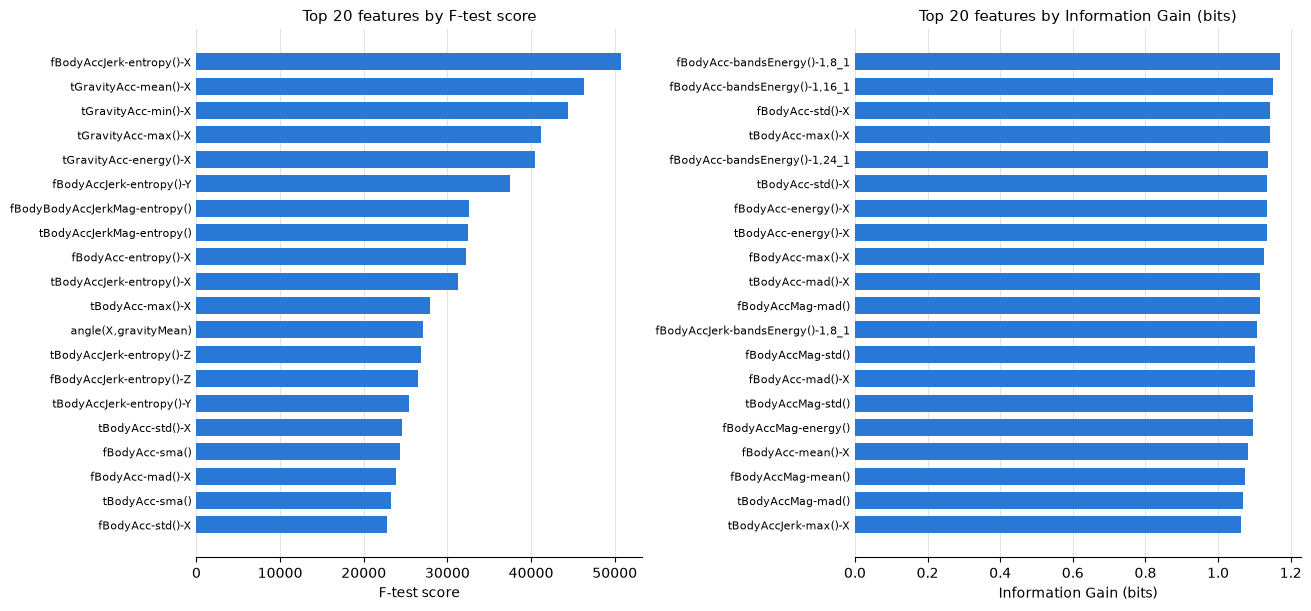

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), layout="constrained")
panels = [(top_f, "f_score", "F-test score"), (top_ig, "information_gain", "Information Gain (bits)")]
for ax, (top, measure, label) in zip(axes, panels):
    ax.barh(top.index, top[measure], color="#2a78d6", height=0.7)
    ax.invert_yaxis()
    ax.set_xlabel(label)
    ax.set_title(f"Top 20 features by {label}", fontsize=11)
    ax.tick_params(axis="y", labelsize=8, length=0)
    ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)

fig.savefig(IMPORTANCE_DIR / "top_features.png", dpi=300)
plt.show()

#### Agreement between the measures

In [26]:
agreement = importance["f_score"].corr(importance["information_gain"], method="spearman")
both = top_f.index.intersection(top_ig.index)

print(f"Spearman correlation between the two rankings: {agreement:.3f}")
print(f"Features in both top 20 lists: {len(both)}")
list(both)

Spearman correlation between the two rankings: 0.789
Features in both top 20 lists: 4


['tBodyAcc-max()-X',
 'tBodyAcc-std()-X',
 'fBodyAcc-mad()-X',
 'fBodyAcc-std()-X']

#### Importance by feature family

The median scores summarise the features by statistic, sensor and domain.

In [27]:
names = importance.index.to_series()
families = pd.DataFrame({
    "statistic": names.map(lambda name: name.split("-")[1].split("(")[0] if "-" in name else "angle"),
    "sensor": names.map(lambda name: "angle" if "-" not in name else "gyroscope" if "Gyro" in name else "gravity" if "Gravity" in name else "body acceleration"),
    "domain": names.map(lambda name: "angle" if "-" not in name else "time" if name[0] == "t" else "frequency"),
})

for family in families.columns:
    summary = importance.groupby(families[family]).median().sort_values("information_gain", ascending=False)
    summary.insert(0, "features", families[family].value_counts())
    display(summary.round(3))

,features,f_score,information_gain
statistic,,,
sma,8,15856.729,0.991
energy,32,3078.634,0.978
mad,32,9391.151,0.971
std,32,8626.250,0.964
iqr,32,7608.553,0.959
max,32,6462.381,0.947
entropy,32,13554.500,0.945
bandsEnergy,126,1633.785,0.939
mean,32,6795.419,0.916


,features,f_score,information_gain
sensor,,,
body acceleration,286,2516.609,0.938
gyroscope,207,1474.772,0.905
angle,7,44.482,0.462
gravity,40,519.217,0.419


,features,f_score,information_gain
domain,,,
frequency,285,1862.782,0.934
time,248,2176.630,0.675
angle,7,44.482,0.462


#### Sitting vs. standing

The overall ranking is likely to reflect the difference between static and dynamic activities, which could hide what separates two similar postures. The same measures are applied here to these two activities only, with the bins computed again on their instances.

In [28]:
is_posture = data["activity"].isin(["SITTING", "STANDING"]).to_numpy()
posture = importance_scores(X.loc[is_posture, distinct], activity[is_posture])
posture.to_csv(IMPORTANCE_DIR / "importance_sitting_standing.csv")

top_posture = top_features(posture, "information_gain")
top_posture["overall_rank"] = importance["information_gain"].rank(ascending=False).astype(int)[top_posture.index]

print(f"{is_posture.sum()} instances, maximum possible Information Gain: {entropy(np.bincount(activity[is_posture])):.3f} bits")
print(f"Spearman correlation between the two rankings: {posture['f_score'].corr(posture['information_gain'], method='spearman'):.3f}")
print(f"Features also in the overall top 20: {len(top_posture.index.intersection(top_ig.index))}")
print(f"Median Information Gain: {posture['information_gain'].median():.3f} bits, maximum: {posture['information_gain'].max():.3f} bits")
top_posture

3683 instances, maximum possible Information Gain: 0.999 bits
Spearman correlation between the two rankings: 0.619
Features also in the overall top 20: 0
Median Information Gain: 0.011 bits, maximum: 0.509 bits


,f_score,information_gain,strong_partners,overall_rank
"angle(Y,gravityMean)",3016.491221,0.508746,3,225
tGravityAcc-mean()-Y,3137.245758,0.508040,3,228
tGravityAcc-max()-Y,3176.771094,0.505716,3,274
tGravityAcc-min()-Y,2914.186128,0.487266,3,227
tGravityAcc-max()-Z,813.353095,0.221346,3,363
"angle(Z,gravityMean)",809.071068,0.220028,3,358
tGravityAcc-mean()-Z,803.927765,0.217706,3,360
tGravityAcc-min()-Z,769.172318,0.206642,3,356
fBodyGyro-meanFreq()-X,1215.225904,0.204021,0,472
tBodyGyro-max()-X,419.031982,0.202191,2,273


## 2. Data statistics

### Dataset overview

In [29]:
STATISTICS_DIR = CSV_DIR / "analysis" / "statistics"
STATISTICS_DIR.mkdir(parents=True, exist_ok=True)

split_sizes = {split: len(pd.read_csv(CSV_DIR / f"{split}.csv", usecols=["subject"])) for split in ["train", "test"]}

pd.Series({
    "Instances": len(data),
    "Training instances": split_sizes["train"],
    "Test instances": split_sizes["test"],
    "Features": X.shape[1],
    "Distinct features": len(distinct),
    "Volunteers": data["subject"].nunique(),
    "Activities": data["activity"].nunique(),
    "Missing values": X.isna().sum().sum(),
    "Repeated rows (features only)": X.duplicated().sum(),
}, name="Value").to_frame()

,Value
Instances,10299
Training instances,7352
Test instances,2947
Features,561
Distinct features,540
Volunteers,30
Activities,6
Missing values,0
Repeated rows (features only),0


### Feature statistics

The features were normalized to the interval [-1, 1], so their values have no physical units and can only be compared relative to each feature's range. The full table is saved as a CSV file. The table below shows the lowest, median and highest value of each statistic across the features.

In [30]:
feature_statistics = X.describe().T.drop(columns="count")
feature_statistics.to_csv(STATISTICS_DIR / "feature_statistics.csv")

print(f"Features reaching -1: {(feature_statistics['min'] == -1).sum()}, reaching 1: {(feature_statistics['max'] == 1).sum()}")
print(f"Values exactly at -1: {(X == -1).to_numpy().mean() * 100:.2f}%, exactly at 1: {(X == 1).to_numpy().mean() * 100:.2f}%")
feature_statistics.describe().loc[["min", "50%", "max"]].round(3)

Features reaching -1: 561, reaching 1: 561
Values exactly at -1: 1.28%, exactly at 1: 0.01%


,mean,std,min,25%,50%,75%,max
min,-0.985,0.037,-1.0,-1.000,-1.000,-0.991,1.0
50%,-0.660,0.263,-1.0,-0.986,-0.907,-0.401,1.0
max,0.830,0.749,-1.0,0.817,0.959,0.994,1.0


Median statistics of the distinct features in each family.

In [31]:
for family in families.columns:
    summary = feature_statistics.loc[distinct].groupby(families[family]).median().sort_values("std", ascending=False)
    summary.insert(0, "features", families[family].value_counts())
    display(summary.round(3))

,features,mean,std,min,25%,50%,75%,max
statistic,,,,,,,,
entropy,32,-0.128,0.609,-1.0,-0.724,-0.267,0.498,1.0
angle,7,0.003,0.447,-1.0,-0.287,0.008,0.251,1.0
sma,8,-0.611,0.397,-1.0,-0.985,-0.899,-0.242,1.0
mad,32,-0.657,0.368,-1.0,-0.987,-0.928,-0.350,1.0
correlation,15,0.003,0.358,-1.0,-0.310,-0.008,0.219,1.0
std,32,-0.668,0.356,-1.0,-0.988,-0.927,-0.405,1.0
kurtosis,13,-0.582,0.339,-1.0,-0.844,-0.703,-0.439,1.0
mean,32,-0.543,0.329,-1.0,-0.979,-0.843,-0.112,1.0
skewness,13,-0.268,0.323,-1.0,-0.526,-0.335,-0.085,1.0


,features,mean,std,min,25%,50%,75%,max
sensor,,,,,,,,
angle,7,0.003,0.447,-1.0,-0.287,0.008,0.251,1.0
gravity,40,-0.226,0.292,-1.0,-0.584,-0.280,-0.013,1.0
body acceleration,286,-0.659,0.257,-1.0,-0.989,-0.941,-0.383,1.0
gyroscope,207,-0.712,0.252,-1.0,-0.985,-0.906,-0.478,1.0


,features,mean,std,min,25%,50%,75%,max
domain,,,,,,,,
angle,7,0.003,0.447,-1.0,-0.287,0.008,0.251,1.0
time,248,-0.120,0.277,-1.0,-0.527,-0.165,0.014,1.0
frequency,285,-0.837,0.232,-1.0,-1.000,-0.975,-0.737,1.0


In [32]:
feature_statistics.nlargest(10, "std").round(3)

,mean,std,min,25%,50%,75%,max
fBodyAccJerk-entropy()-X,-0.267,0.749,-1.0,-1.000,-0.679,0.520,1.0
fBodyAccJerk-entropy()-Y,-0.266,0.734,-1.0,-1.000,-0.618,0.508,1.0
tBodyAccJerkMag-entropy(),-0.062,0.724,-1.0,-0.802,-0.320,0.703,1.0
fBodyAcc-entropy()-X,-0.200,0.723,-1.0,-0.946,-0.498,0.549,1.0
"tGravityAcc-correlation()-X,Z",-0.108,0.704,-1.0,-0.806,-0.217,0.591,1.0
"tGravityAcc-correlation()-Y,Z",0.085,0.701,-1.0,-0.609,0.175,0.776,1.0
tGravityAcc-energy()-X,0.446,0.696,-1.0,0.521,0.791,0.877,1.0
"tGravityAcc-correlation()-X,Y",0.176,0.696,-1.0,-0.490,0.361,0.838,1.0
tBodyGyroJerkMag-entropy(),0.131,0.692,-1.0,-0.572,0.084,0.842,1.0
fBodyAccMag-entropy(),-0.190,0.678,-1.0,-0.873,-0.355,0.491,1.0


In [33]:
feature_statistics.nsmallest(10, "std").round(3)

,mean,std,min,25%,50%,75%,max
tBodyAcc-mean()-Y,-0.018,0.037,-1.0,-0.025,-0.017,-0.011,1.0
tBodyAcc-mean()-Z,-0.109,0.053,-1.0,-0.121,-0.109,-0.098,1.0
"fBodyAccJerk-bandsEnergy()-57,64_1",-0.985,0.054,-1.0,-1.000,-1.000,-0.991,1.0
"fBodyGyro-bandsEnergy()-33,40_2",-0.978,0.058,-1.0,-1.000,-0.999,-0.976,1.0
"fBodyGyro-bandsEnergy()-33,48_2",-0.973,0.065,-1.0,-1.000,-0.999,-0.970,1.0
"fBodyGyro-bandsEnergy()-33,40_3",-0.971,0.066,-1.0,-1.000,-0.999,-0.966,1.0
tBodyAcc-mean()-X,0.274,0.068,-1.0,0.263,0.277,0.288,1.0
"fBodyGyro-bandsEnergy()-33,48_3",-0.968,0.068,-1.0,-1.000,-0.998,-0.961,1.0
"fBodyGyro-bandsEnergy()-25,48_3",-0.966,0.071,-1.0,-1.000,-0.999,-0.959,1.0
"fBodyGyro-bandsEnergy()-57,64_1",-0.975,0.072,-1.0,-1.000,-0.999,-0.984,1.0


Features with the largest share of values exactly at the limits of the interval.

In [34]:
at_limits = pd.DataFrame({"at -1 (%)": (X == -1).mean() * 100, "at 1 (%)": (X == 1).mean() * 100})
at_limits.loc[at_limits.sum(axis=1).nlargest(10).index].round(2)

,at -1 (%),at 1 (%)
tGravityAcc-entropy()-Y,73.13,0.02
tGravityAcc-entropy()-Z,45.50,0.01
tGravityAcc-entropy()-X,43.22,0.01
fBodyGyro-maxInds-X,42.19,0.03
fBodyAcc-maxInds-Z,40.95,0.01
fBodyAccJerk-entropy()-X,40.90,0.01
fBodyBodyGyroMag-maxInds,40.69,0.01
fBodyAccJerk-entropy()-Y,38.02,0.01
fBodyBodyAccJerkMag-entropy(),37.77,0.01
fBodyAccJerk-entropy()-Z,35.23,0.01


### Activity and volunteer statistics

In [35]:
activity_order = data.drop_duplicates("activity_id").sort_values("activity_id")["activity"]

activity_counts = data["activity"].value_counts().reindex(activity_order).to_frame("instances")
activity_counts["share (%)"] = (activity_counts["instances"] / len(data) * 100).round(1)

print(f"Ratio between the largest and the smallest class: {activity_counts['instances'].max() / activity_counts['instances'].min():.2f}")
activity_counts

Ratio between the largest and the smallest class: 1.38


,instances,share (%)
activity,,
WALKING,1722,16.7
WALKING_UPSTAIRS,1544,15.0
WALKING_DOWNSTAIRS,1406,13.7
SITTING,1777,17.3
STANDING,1906,18.5
LAYING,1944,18.9


In [36]:
volunteer_activity = pd.crosstab(data["subject"], data["activity"])[activity_order]
volunteer_activity.to_csv(STATISTICS_DIR / "volunteer_activity.csv")
per_volunteer = volunteer_activity.sum(axis=1)

print(f"Instances per volunteer: min {per_volunteer.min()} (volunteer {per_volunteer.idxmin()}), median {per_volunteer.median():.0f}, max {per_volunteer.max()} (volunteer {per_volunteer.idxmax()})")
print(f"Instances per volunteer and activity: min {volunteer_activity.to_numpy().min()}, median {np.median(volunteer_activity):.0f}, max {volunteer_activity.to_numpy().max()}")
print(f"Volunteer and activity combinations with no instances: {(volunteer_activity == 0).sum().sum()}")
volunteer_activity

Instances per volunteer: min 281 (volunteer 8), median 342, max 409 (volunteer 25)
Instances per volunteer and activity: min 36, median 54, max 95
Volunteer and activity combinations with no instances: 0


activity,WALKING,WALKING_UPSTAIRS,WALKING_DOWNSTAIRS,SITTING,STANDING,LAYING
subject,,,,,,
1,95,53,49,47,53,50
2,59,48,47,46,54,48
3,58,59,49,52,61,62
4,60,52,45,50,56,54
5,56,47,47,44,56,52
6,57,51,48,55,57,57
7,57,51,47,48,53,52
8,48,41,38,46,54,54
9,52,49,42,50,45,50


### Statistics by activity

Mean and standard deviation, for the top features from the importance section and for the top features that separate sitting from standing.

In [37]:
selected = list(dict.fromkeys([*top_ig.index[:4], *top_f.index[:2], *top_posture.index[:2]]))

grouped = data.groupby("activity")[selected]
by_activity = grouped.mean().map("{:.3f}".format) + " ± " + grouped.std().map("{:.3f}".format)
by_activity = by_activity.T[activity_order]
by_activity.to_csv(STATISTICS_DIR / "statistics_by_activity.csv")
by_activity

activity,WALKING,WALKING_UPSTAIRS,WALKING_DOWNSTAIRS,SITTING,STANDING,LAYING
"fBodyAcc-bandsEnergy()-1,8_1",-0.772 ± 0.103,-0.671 ± 0.130,-0.316 ± 0.293,-0.999 ± 0.005,-1.000 ± 0.002,-0.995 ± 0.031
"fBodyAcc-bandsEnergy()-1,16_1",-0.760 ± 0.103,-0.684 ± 0.121,-0.342 ± 0.270,-0.999 ± 0.004,-1.000 ± 0.002,-0.996 ± 0.026
fBodyAcc-std()-X,-0.323 ± 0.146,-0.219 ± 0.151,0.122 ± 0.242,-0.984 ± 0.034,-0.986 ± 0.023,-0.959 ± 0.081
tBodyAcc-max()-X,-0.113 ± 0.215,-0.015 ± 0.194,0.417 ± 0.203,-0.927 ± 0.037,-0.921 ± 0.040,-0.912 ± 0.048
fBodyAccJerk-entropy()-X,0.518 ± 0.138,0.447 ± 0.152,0.659 ± 0.147,-0.950 ± 0.122,-0.921 ± 0.168,-0.934 ± 0.155
tGravityAcc-mean()-X,0.935 ± 0.037,0.875 ± 0.070,0.926 ± 0.036,0.880 ± 0.135,0.941 ± 0.034,-0.375 ± 0.190
"angle(Y,gravityMean)",0.219 ± 0.066,0.279 ± 0.085,0.200 ± 0.065,0.006 ± 0.141,0.210 ± 0.076,-0.436 ± 0.336
tGravityAcc-mean()-Y,-0.197 ± 0.096,-0.281 ± 0.121,-0.169 ± 0.094,0.109 ± 0.197,-0.184 ± 0.111,0.622 ± 0.371


## 3. Data distribution

### Shape of the features

The skewness measures how lopsided a distribution is (0 for a symmetric one). The kurtosis measures how heavy its tails are (0 for a normal distribution). A feature is roughly symmetric when |skewness| < 0.5, moderately skewed between 0.5 and 1, and highly skewed above 1.

In [38]:
from scipy.stats import ks_2samp

DISTRIBUTION_DIR = CSV_DIR / "analysis" / "distribution"
DISTRIBUTION_DIR.mkdir(parents=True, exist_ok=True)

distribution = pd.DataFrame({"skewness": X.skew(), "kurtosis": X.kurt()})
distribution["shape"] = pd.cut(distribution["skewness"].abs(), [0, 0.5, 1, np.inf], right=False,
                               labels=["roughly symmetric", "moderately skewed", "highly skewed"])

distribution["shape"].value_counts()

shape
highly skewed        271
roughly symmetric    165
moderately skewed    125
Name: count, dtype: int64

### Histograms of typical shapes

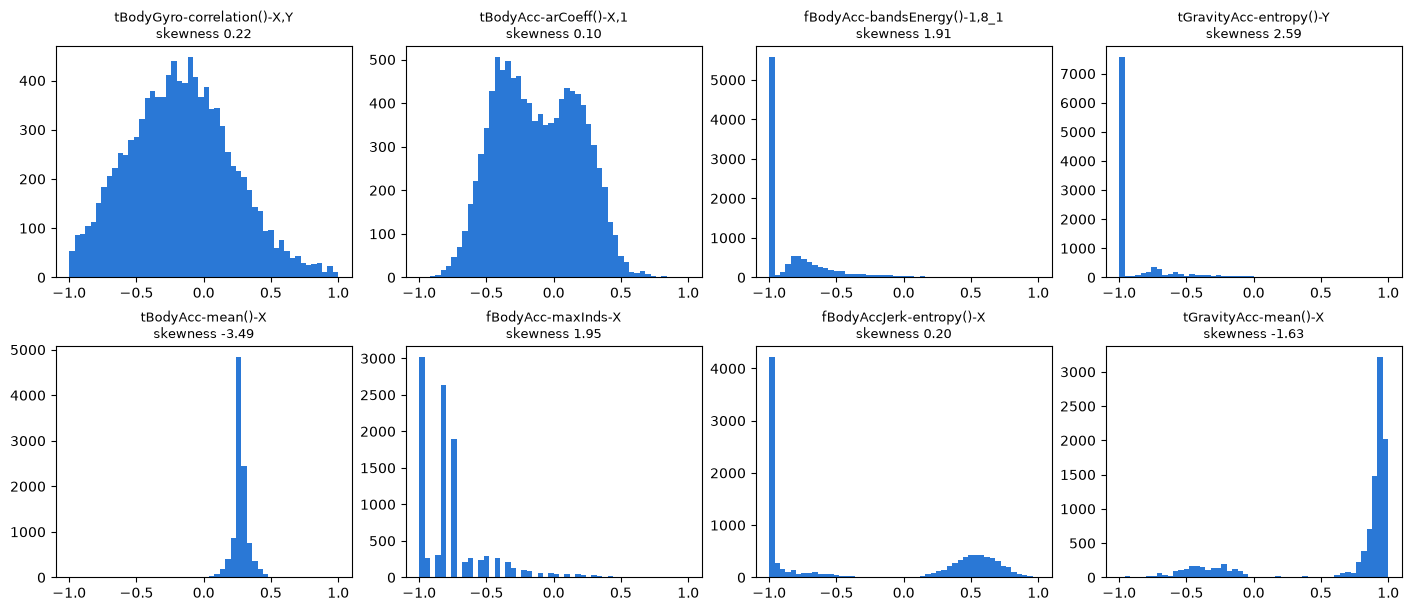

In [39]:
examples = [
    "tBodyGyro-correlation()-X,Y", "tBodyAcc-arCoeff()-X,1", "fBodyAcc-bandsEnergy()-1,8_1", "tGravityAcc-entropy()-Y",
    "tBodyAcc-mean()-X", "fBodyAcc-maxInds-X", "fBodyAccJerk-entropy()-X", "tGravityAcc-mean()-X",
]

fig, axes = plt.subplots(2, 4, figsize=(14, 6), layout="constrained")
for ax, feature in zip(axes.flat, examples):
    ax.hist(X[feature], bins=50, color="#2a78d6")
    ax.set_title(f"{feature}\nskewness {distribution.loc[feature, 'skewness']:.2f}", fontsize=9)

fig.savefig(DISTRIBUTION_DIR / "histograms.png", dpi=300)
plt.show()

### Distribution by activity

Box plots of the features from the statistics by activity table: the box spans the quartiles, the line is the median, and the points are values more than 1.5 times the interquartile range away from the box.

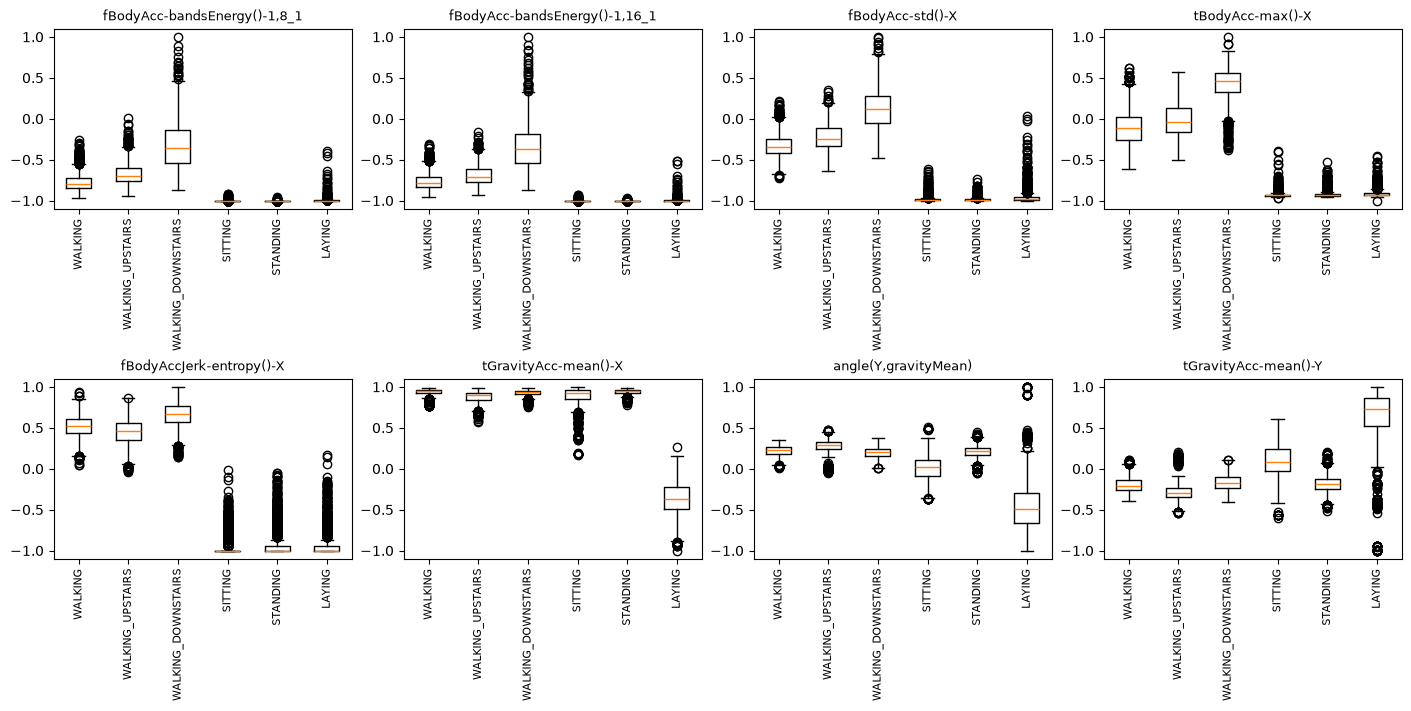

In [40]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7), layout="constrained")
for ax, feature in zip(axes.flat, selected):
    ax.boxplot([data.loc[data["activity"] == activity, feature] for activity in activity_order], tick_labels=activity_order)
    ax.tick_params(axis="x", rotation=90, labelsize=8)
    ax.set_title(feature, fontsize=9)

fig.savefig(DISTRIBUTION_DIR / "boxplots_by_activity.png", dpi=300)
plt.show()

### Outliers

A value is an outlier when it is more than 1.5 times the interquartile range below the first quartile or above the third quartile, the same rule as in the box plots. In skewed features, many of these values are part of the long tail rather than errors.

In [41]:
q1, q3 = X.quantile(0.25), X.quantile(0.75)
iqr = q3 - q1
distribution["outliers (%)"] = ((X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)).mean() * 100

distribution["outliers (%)"].describe().round(2)

count    561.00
mean       3.88
std        5.37
min        0.00
25%        0.24
50%        1.16
75%        6.80
max       37.59
Name: outliers (%), dtype: float64

### Training vs. test data

The Kolmogorov-Smirnov statistic is the largest gap between the cumulative distributions of a feature in the training and the test data, from 0 (identical) to 1 (completely different).

In [42]:
is_train = np.arange(len(data)) < split_sizes["train"]
distribution["train_test_ks"] = [ks_2samp(X.loc[is_train, f], X.loc[~is_train, f]).statistic for f in X.columns]

distribution.to_csv(DISTRIBUTION_DIR / "distribution.csv")
distribution["train_test_ks"].describe().round(3)

count    561.000
mean       0.055
std        0.019
min        0.014
25%        0.041
50%        0.056
75%        0.069
max        0.114
Name: train_test_ks, dtype: float64

## 4. Data visualization

Each chart shows all the instances in two dimensions. There is one panel per activity: the instances of that activity are shown in blue, on top of all the other instances in grey.

In [43]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

VISUALIZATION_DIR = CSV_DIR / "analysis" / "visualization"
VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)


def plot_by_activity(points, xlabel, ylabel, file_name):
    fig, axes = plt.subplots(2, 3, figsize=(12, 7.5), sharex=True, sharey=True, layout="constrained")
    for ax, activity in zip(axes.flat, activity_order):
        is_activity = (data["activity"] == activity).to_numpy()
        ax.scatter(points[:, 0], points[:, 1], s=2, color="#d3d1cb")
        ax.scatter(points[is_activity, 0], points[is_activity, 1], s=2, color="#2a78d6")
        ax.set_title(activity, fontsize=10)
    for ax in axes[1]:
        ax.set_xlabel(xlabel)
    for ax in axes[:, 0]:
        ax.set_ylabel(ylabel)
    fig.savefig(VISUALIZATION_DIR / file_name, dpi=300)
    plt.show()

### Principal component analysis (PCA)

PCA projects the features onto the two directions along which the data varies the most.

Variance explained: 60.8% and 4.8%


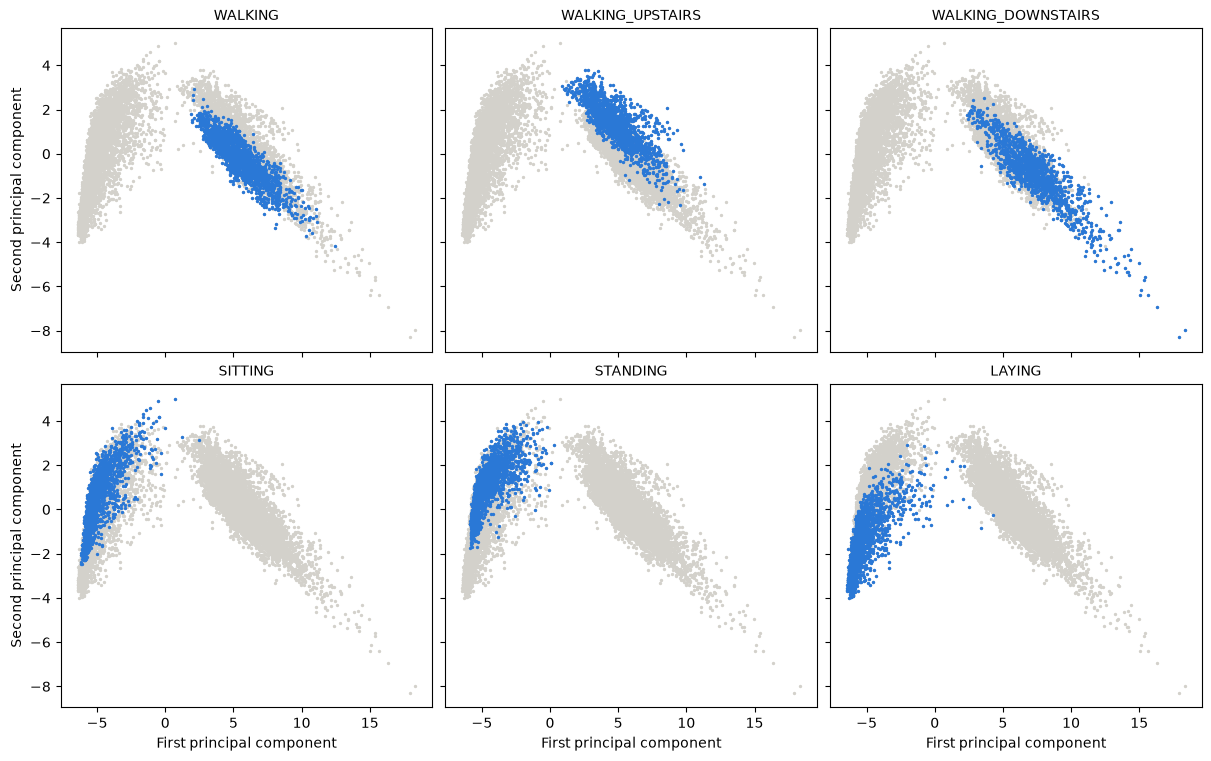

In [44]:
pca = PCA(n_components=2).fit(X[distinct])
print(f"Variance explained: {pca.explained_variance_ratio_[0] * 100:.1f}% and {pca.explained_variance_ratio_[1] * 100:.1f}%")

plot_by_activity(pca.transform(X[distinct]), "First principal component", "Second principal component", "pca.png")

### Two features

A movement feature and a gravity feature from the previous sections.

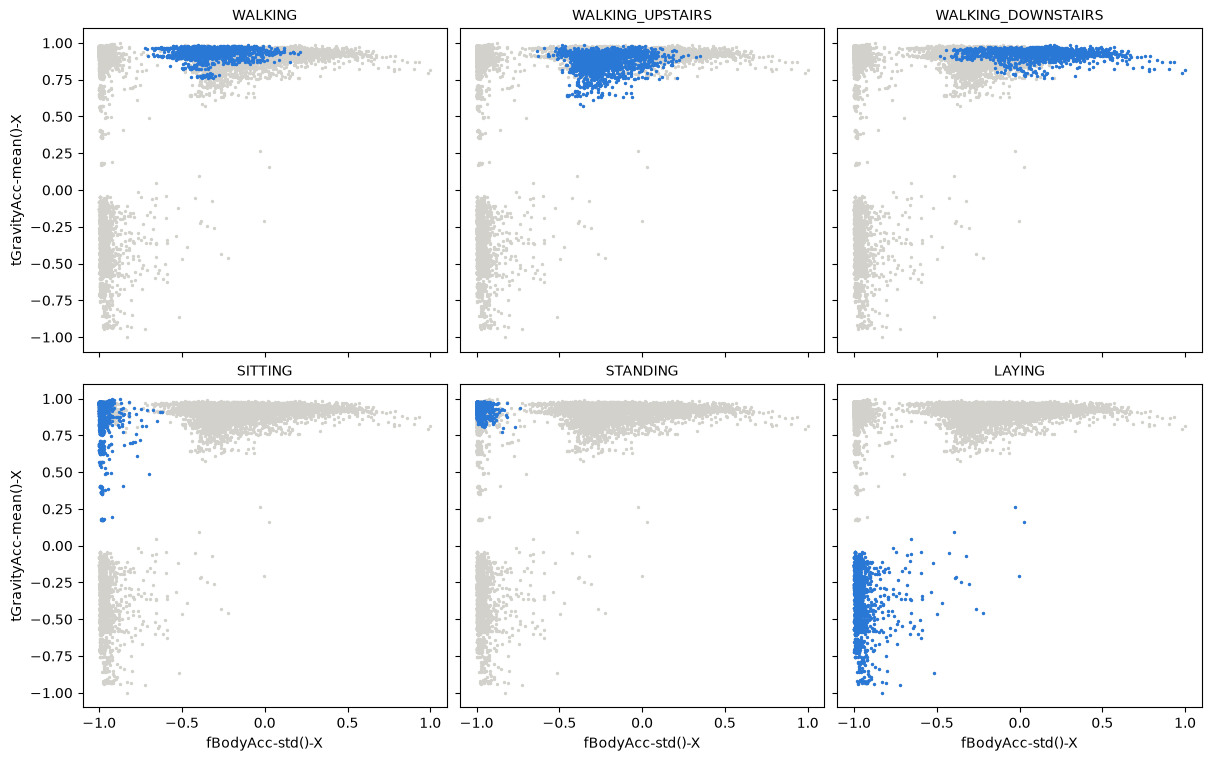

In [45]:
plot_by_activity(data[["fBodyAcc-std()-X", "tGravityAcc-mean()-X"]].to_numpy(), "fBodyAcc-std()-X", "tGravityAcc-mean()-X", "two_features.png")

### t-SNE

t-SNE places instances that are similar in the 561 features close to each other in two dimensions. Unlike PCA, the axes have no meaning and the distances between groups are not reliable; only which instances end up close together is.

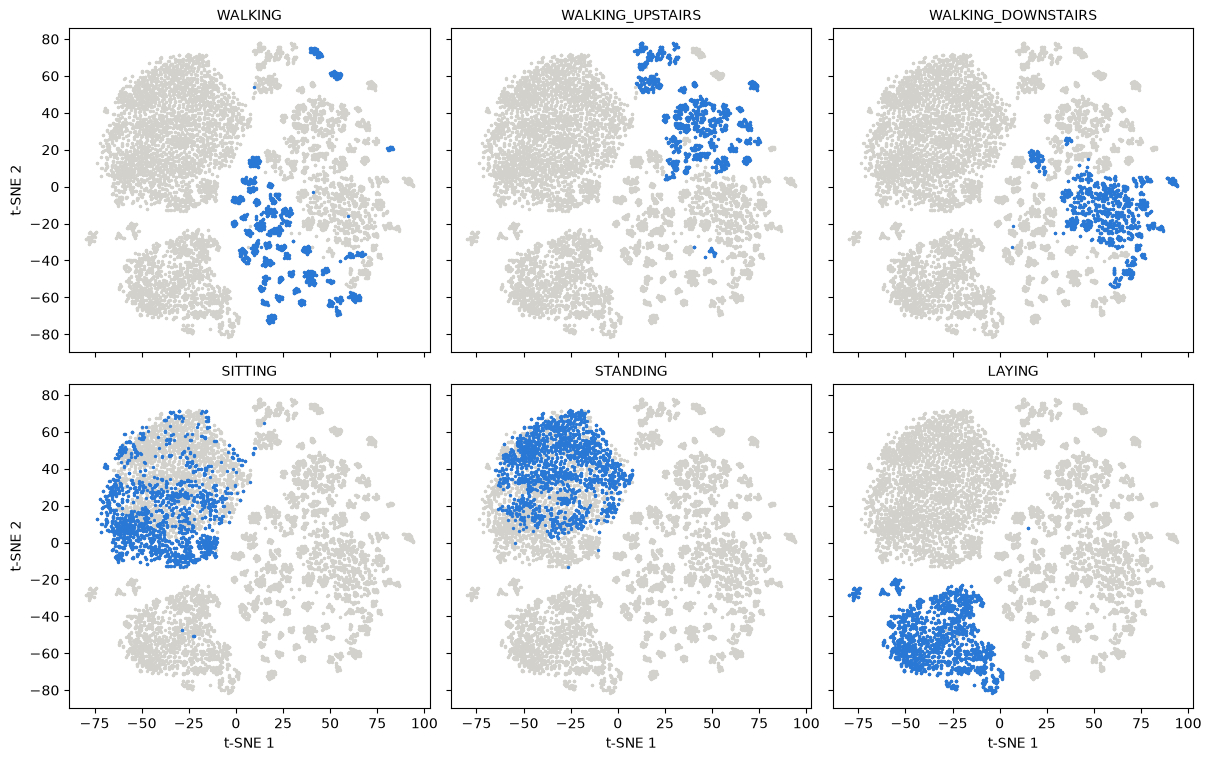

In [46]:
embedding = TSNE(n_components=2, random_state=0).fit_transform(X[distinct])

plot_by_activity(embedding, "t-SNE 1", "t-SNE 2", "tsne.png")